In [171]:
import importlib
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

CODE_DIR = Path.cwd().parent if Path.cwd().name == "train-notebooks" else Path.cwd()
if not ((CODE_DIR / "kev").is_dir() and (CODE_DIR / "data").is_dir() and (CODE_DIR / "training").is_dir()):
    raise RuntimeError(f"Expected code/ root containing kev/, data/, and training/; got {CODE_DIR}")
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev")):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import data.persona as _persona_mod
import data.base as _base_mod
import data.marginals as _marginals_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.grummon as _grummon_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training.iid_trainer as _iid_trainer_mod
import training.marginal_trainer as _marginal_trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _marginals_mod,
    _issp_mod,
    _twin2k_mod,
    _grummon_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _iid_trainer_mod,
    _marginal_trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_eval_set, build_persona_dataset
from data.grummon import load_grummon
from data.issp import load_issp_df
from data.marginals import DEFAULT_K_SCHEDULE, build_marginal_lookup
from data.twin2k import load_twin2k_df
from training import MarginalGroupedTrainer, free_gpu

print(f"Working directory: {Path.cwd()}")




Working directory: /home/dw/github/decision-models-finetuning/code


## 1. Load & Build Persona Datasets

In [172]:
INCLUDE_COUNTRY = False
VALID_SEED = 0
N_ISSP_PER_YEAR = 4
N_TWIN_FAMILIES = 40
MAX_VALID_RESP_PER_QID = 100
SIM_THRESHOLD = 0.95

issp_df = load_issp_df()
twin_df = load_twin2k_df()
all_df = pd.concat([issp_df, twin_df], ignore_index=True)
q_text_map = all_df.groupby("qid")["question"].first().str.strip().to_dict()

print(
    f"ISSP    : {len(issp_df):>10,} rows | {issp_df['qid'].nunique():>4} questions\n"
    f"Twin-2K : {len(twin_df):>10,} rows | {twin_df['qid'].nunique():>4} questions\n"
    f"Total   : {len(all_df):>10,} rows | {all_df['qid'].nunique():>4} questions"
)


ISSP    :    767,484 rows |  616 questions
Twin-2K :  1,127,649 rows |  974 questions
Total   :  1,895,133 rows | 1590 questions


In [173]:
import random

rng = random.Random(VALID_SEED)

valid_by_group = {}
candidate_queues = {}
issp_summary_rows = []

for yr, grp in sorted(issp_df.groupby(issp_df["qid"].str.split(":").str[0])):
    qids = sorted(grp["qid"].unique())
    shuffled = rng.sample(qids, len(qids))
    valid_by_group[yr] = shuffled[:N_ISSP_PER_YEAR]
    candidate_queues[yr] = shuffled[N_ISSP_PER_YEAR:]
    issp_summary_rows.append({
        "year": yr,
        "total_qids": len(qids),
        "initial_candidates": ", ".join(valid_by_group[yr]),
        "backups": len(candidate_queues[yr]),
    })

display(pd.DataFrame(issp_summary_rows))


,year,total_qids,initial_candidates,backups
0,2015,82,"2015:v54, 2015:v58, 2015:v13, 2015:v4",78
1,2016,60,"2016:v28, 2016:v42, 2016:v23, 2016:v26",56
2,2017,60,"2017:v57, 2017:v42, 2017:v46, 2017:v40",56
3,2018,62,"2018:v29, 2018:v42, 2018:v24, 2018:v16",58
4,2019,49,"2019:v57, 2019:v61, 2019:v2, 2019:v28",45
5,2020,55,"2020:v38, 2020:v33, 2020:v47, 2020:v14",51
6,2021,58,"2021:v25, 2021:v19, 2021:v18, 2021:v43",54
7,2022,55,"2022:v47, 2022:v45, 2022:v28, 2022:v40",51
8,2023,60,"2023:v1, 2023:v29, 2023:v52, 2023:v54",56
9,2024,75,"2024:v44, 2024:v68, 2024:v75, 2024:v39",71


In [174]:
import random

rng = random.Random(VALID_SEED)

twin_by_family = {}
for qid in sorted(twin_df["qid"].unique()):
    fam = qid.split("_")[0]
    twin_by_family.setdefault(fam, []).append(qid)

shuffled_families = rng.sample(sorted(twin_by_family), len(twin_by_family))
twin_pool = [rng.choice(twin_by_family[fam]) for fam in shuffled_families]
valid_by_group["twin2k"] = twin_pool[:N_TWIN_FAMILIES]
candidate_queues["twin2k"] = twin_pool[N_TWIN_FAMILIES:]

print(
    f"Twin-2K families   : {len(twin_by_family)} total\n"
    f"Initial candidates : {len(valid_by_group['twin2k'])} ({len(candidate_queues['twin2k'])} backup families)\n"
    f"Sampled Twin-2K    : {valid_by_group['twin2k'][:10]} ..."
)

Twin-2K families   : 119 total
Initial candidates : 40 (79 backup families)
Sampled Twin-2K    : ['twin2k:QID75', 'twin2k:QID237_8', 'twin2k:QID63', 'twin2k:QID80', 'twin2k:QID245_4', 'twin2k:QID151', 'twin2k:QID194', 'twin2k:QID273', 'twin2k:QID27_12', 'twin2k:QID239_2'] ...


In [175]:
import numpy as np
from rapidfuzz import fuzz, process

def find_train_matches(valid_qids, q_text_map, threshold=SIM_THRESHOLD):
    valid_set = set(valid_qids)
    train_qids = [q for q in q_text_map if q not in valid_set]
    scores = process.cdist(
        [q_text_map[q] for q in valid_qids],
        [q_text_map[q] for q in train_qids],
        scorer=fuzz.ratio,
        dtype=np.float64,
        workers=-1,
    ) / 100.0
    best = scores.argmax(axis=1)
    return {
        vq: (train_qids[j], float(scores[i, j]))
        for i, (vq, j) in enumerate(zip(valid_qids, best))
        if scores[i, j] >= threshold
    }

round_idx = 0
while True:
    round_idx += 1
    current_valid = [q for grp in sorted(valid_by_group) for q in valid_by_group[grp]]
    matches = find_train_matches(current_valid, q_text_map, threshold=SIM_THRESHOLD)
    if not matches:
        print(f"\nRound {round_idx}: 0 matches >= {SIM_THRESHOLD}. All {len(current_valid)} valid questions passed!")
        break

    print(f"\n=== Round {round_idx}: {len(matches)} valid question(s) matched train (>= {SIM_THRESHOLD}) ===")
    for grp in sorted(valid_by_group):
        for i, vq in enumerate(valid_by_group[grp]):
            if vq in matches:
                tq, sim = matches[vq]
                replacement = candidate_queues[grp].pop(0)
                print(
                    f"[{grp}] {vq} -> replaced with {replacement} (matched {tq}, sim={sim:.3f})\n"
                    f"  Valid: {q_text_map[vq]}\n"
                    f"  Train: {q_text_map[tq]}"
                )
                valid_by_group[grp][i] = replacement

VALID_ISSP_QIDS = [q for grp in sorted(valid_by_group) if grp != "twin2k" for q in valid_by_group[grp]]
VALID_TWIN_QIDS = list(valid_by_group["twin2k"])
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS


=== Round 1: 21 valid question(s) matched train (>= 0.95) ===
[2016] 2016:v42 -> replaced with 2016:v2 (matched 2016:v41, sim=0.975)
  Valid: Some people think that governments should have the right to take certain measures in the name of national security. Others disagree. Do you think that the United States' government should or should not have the right to do the following: collect information about anyone living in other countries without their knowledge
  Train: Some people think that governments should have the right to take certain measures in the name of national security. Others disagree. Do you think that the United States' government should or should not have the right to do the following: collect information about anyone living in the United States without their knowledge
[2016] 2016:v26 -> replaced with 2016:v20 (matched 2016:v24, sim=0.969)
  Valid: On the whole, do you think it should or should not be the government's responsibility to ... ... provide a decent standard 

In [176]:
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS
if len(VALID_QIDS) != len(set(VALID_QIDS)):
    raise ValueError("Duplicate qids in VALID_QIDS")
if not set(VALID_QIDS) <= set(all_df["qid"]):
    raise KeyError(f"Valid qids not found: {sorted(set(VALID_QIDS) - set(all_df['qid']))}")

train_df = all_df[~all_df["qid"].isin(VALID_QIDS)].reset_index(drop=True)
valid_full_df = all_df[all_df["qid"].isin(VALID_QIDS)]
valid_df = pd.concat(
    [
        g.sample(n=min(len(g), MAX_VALID_RESP_PER_QID), random_state=VALID_SEED)
        for _, g in valid_full_df.groupby("qid", sort=True)
    ],
    ignore_index=True,
)

if not set(train_df["qid"]).isdisjoint(valid_df["qid"]):
    raise AssertionError("Leakage detected between train_df and valid_df qids")

print(
    f"train_df      : {len(train_df):>10,} rows | {train_df['qid'].nunique():>4} questions\n"
    f"valid_full_df : {len(valid_full_df):>10,} rows | {valid_full_df['qid'].nunique():>4} questions (all excluded from train)\n"
    f"valid_df (sub): {len(valid_df):>10,} rows | {valid_df['qid'].nunique():>4} questions (<= {MAX_VALID_RESP_PER_QID} resp/question)"
)

train_df      :  1,764,410 rows | 1510 questions
valid_full_df :    130,723 rows |   80 questions (all excluded from train)
valid_df (sub):      8,000 rows |   80 questions (<= 100 resp/question)


### Check max valid/train question similarity

In [177]:
valid_set = sorted(valid_df["qid"].unique())
train_qids = sorted(train_df["qid"].unique())
scores = process.cdist(
    [q_text_map[q] for q in valid_set],
    [q_text_map[q] for q in train_qids],
    scorer=fuzz.ratio,
    dtype=np.float64,
    workers=-1,
) / 100.0
best = scores.argmax(axis=1)
matches = {vq: (train_qids[j], float(scores[i, j])) for i, (vq, j) in enumerate(zip(valid_set, best))}
max_sim = max(sim for _, sim in matches.values())

print(f"Max similarity across all {len(valid_set)} valid questions vs {len(train_qids)} train questions: {max_sim:.4f}\n")

top10 = sorted(matches.items(), key=lambda kv: kv[1][1], reverse=True)[:10]
for rank, (vq, (tq, sim)) in enumerate(top10, start=1):
    print(
        f"{rank:2d}. sim={sim:.3f} | valid={vq} vs train={tq}\n"
        f"    Valid: {q_text_map[vq]}\n"
        f"    Train: {q_text_map[tq]}"
    )
    

Max similarity across all 80 valid questions vs 1510 train questions: 0.9494

 1. sim=0.949 | valid=twin2k:QID83 vs train=twin2k:QID78
    Valid: Antonym: Select the word that is most nearly the opposite in meaning to VACUOUS
    Train: Antonym: Select the word that is most nearly the opposite in meaning to VERBOSE
 2. sim=0.948 | valid=twin2k:QID76 vs train=twin2k:QID74
    Valid: Antonym: Select the word that is most nearly the opposite in meaning to ALOOF
    Train: Antonym: Select the word that is most nearly the opposite in meaning to SATED
 3. sim=0.948 | valid=2020:v26 vs train=2020:v27
    Valid: How willing would you be to pay much higher prices in order to protect the environment?
    Train: how willing would you be to pay much higher taxes in order to protect the environment?
 4. sim=0.947 | valid=twin2k:QID65 vs train=twin2k:QID69
    Valid: Synonym: Select the word that is most nearly the same in meaning as SOLICIT
    Train: Synonym: Select the word that is most nearly th

### build datasets

In [178]:
train_records = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_diverse80"
)
marginal_lookup = build_marginal_lookup(train_df, include_country=INCLUDE_COUNTRY)

valid_grouped = build_eval_set(
    valid_df,
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid_diverse80", valid=True,
)
grummon_grouped = load_grummon(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False)

eval_records = [valid_grouped, grummon_grouped]

print(
    f"Train rows    : {len(train_df):,} ({train_df['qid'].nunique():,} questions | "
    f"{marginal_lookup.num_unique_personas:,} unique personas, {len(marginal_lookup.trait_masks)} trait-value masks)\n"
    f"Eval sets     : valid={len(valid_grouped['records']):,} ({len(valid_grouped['packed_views']):,} states), "
    f"grummon={len(grummon_grouped['records']):,} ({len(grummon_grouped['packed_views']):,} states)"
)

Loaded 1,764,410 records from train_records_diverse80_minNone_74398c39.pkl
Loaded 8,000 records from valid_diverse80_records_minNone_0df15406.pkl
Train rows    : 1,764,410 (1,510 questions | 16,338 unique personas, 181 trait-value masks)
Eval sets     : valid=8,000 (3,939 states), grummon=33,798 (3,652 states)


In [179]:
train_rec_qids = set(train_df["qid"].unique())
valid_rec_qids = {r["qid"] for r in valid_grouped["records"]}
grummon_rec_qids = {r["qid"] for r in grummon_grouped["records"]}
all_qids = set(all_df["qid"].unique())

train_rec_texts = set(train_df["question"].str.strip().unique())
valid_rec_texts = {r["question"].strip() for r in valid_grouped["records"]}
grummon_rec_texts = {r["question"].strip() for r in grummon_grouped["records"]}

assert len(valid_grouped["records"]) == len(valid_df), f"{len(valid_grouped['records'])} != {len(valid_df)}"
assert train_rec_qids == all_qids - set(VALID_QIDS)
assert valid_rec_qids == set(VALID_QIDS)
assert train_rec_qids.isdisjoint(valid_rec_qids), f"Train/Valid QID overlap: {train_rec_qids & valid_rec_qids}"
assert train_rec_qids.isdisjoint(grummon_rec_qids), f"Train/Grummon QID overlap: {train_rec_qids & grummon_rec_qids}"
assert valid_rec_qids.isdisjoint(grummon_rec_qids), f"Valid/Grummon QID overlap: {valid_rec_qids & grummon_rec_qids}"
assert train_rec_texts.isdisjoint(valid_rec_texts), "Exact question text overlap between train and valid!"
assert train_rec_texts.isdisjoint(grummon_rec_texts), "Exact question text overlap between train and grummon!"
assert valid_rec_texts.isdisjoint(grummon_rec_texts), "Exact question text overlap between valid and grummon!"

print(
    f"QID counts       : train={len(train_rec_qids):,}, valid={len(valid_rec_qids):,}, grummon={len(grummon_rec_qids):,} "
    f"(train+valid={len(train_rec_qids | valid_rec_qids):,} / {len(all_qids):,} in all_df)\n"
    f"QID overlaps     : train∩valid={len(train_rec_qids & valid_rec_qids)}, "
    f"train∩grummon={len(train_rec_qids & grummon_rec_qids)}, "
    f"valid∩grummon={len(valid_rec_qids & grummon_rec_qids)}\n"
    f"Question overlaps: train∩valid={len(train_rec_texts & valid_rec_texts)}, "
    f"train∩grummon={len(train_rec_texts & grummon_rec_texts)}, "
    f"valid∩grummon={len(valid_rec_texts & grummon_rec_texts)}\n"
    f"All dataset split sanity checks passed!"
)


QID counts       : train=1,510, valid=80, grummon=36 (train+valid=1,590 / 1,590 in all_df)
QID overlaps     : train∩valid=0, train∩grummon=0, valid∩grummon=0
Question overlaps: train∩valid=0, train∩grummon=0, valid∩grummon=0
All dataset split sanity checks passed!


## 2. Preserve & Augment Persona Question Groups ($k$-Marginals)

### 2.1 Build baseline unique-persona question groups (`train_records`, `epoch_base_groups`)

In [156]:
import random
import numpy as np
from data.base import build_persona_dataset, group_train_records, make_grouped_view
from data.persona import PERSONA_NAMES

PERSONA_COLS = [col for col in PERSONA_NAMES if INCLUDE_COUNTRY or col != "c_alphan"]

# 1. Build full-persona records and partition each unique persona's own questions into <=32-question groups
#    (exact same 68,477 groups and 1,764,410 question records as train-grouped-diversevalid-grouped-800m)
train_records = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_diverse80"
)
epoch_base_groups = group_train_records(
    train_records, max_questions=32, max_chars=20_000, rng=random.Random(0)
)

# 2. Inspect Group #0: one unique persona and its corresponding <=32 answered questions
example_base_group = epoch_base_groups[0]
full_persona = example_base_group[0]["personas"]

print(
    f"Total train_records : {len(train_records):,}\n"
    f"Baseline groups     : {len(epoch_base_groups):,} groups (every record used once, no question sampling)\n"
    f"Example Group #0    : {len(example_base_group)} questions | {len(full_persona)} persona traits (year={example_base_group[0]['year']!r})"
)
display(pd.DataFrame(example_base_group)[["qid", "year", "question", "option_texts", "human_dist"]].head(5))


Loaded 1,764,410 records from train_records_diverse80_minNone_74398c39.pkl
Total train_records : 1,764,410
Baseline groups     : 68,477 groups (every record used once, no question sampling)
Example Group #0    : 32 questions | 13 persona traits (year='twin2k')


,qid,year,question,option_texts,human_dist
0,twin2k:QID9_071,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[0.0, 1.0]"
1,twin2k:QID9_216,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1.0, 0.0]"
2,twin2k:QID9_027,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1.0, 0.0]"
3,twin2k:QID9_429,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1.0, 0.0]"
4,twin2k:QID9_435,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1.0, 0.0]"


### 2.2 Sample $k$ traits (`subpersona`) and compute exact marginals on that group's questions (`marginals_df`)

In [157]:
K_SCHEDULE = (1, 2, 3, 4, 5, "full", "full")
sample_rng = random.Random(0)

# 1. Pick k from K_SCHEDULE (1..5 soft marginals + full persona) and sample k observed traits
k_choice = sample_rng.choice(K_SCHEDULE)
k_traits = len(full_persona) if k_choice == "full" else min(k_choice, len(full_persona))
chosen_traits = set(sample_rng.sample(list(full_persona.keys()), k_traits))
subpersona = {col: val for col, val in full_persona.items() if col in chosen_traits}

persona_compare_df = pd.DataFrame({
    "trait": list(full_persona.keys()),
    "value": list(full_persona.values()),
    "in_subpersona": [col in chosen_traits for col in full_persona],
})
print(f"Sampled k_choice={k_choice!r} -> k={k_traits}/{len(full_persona)} traits -> subpersona={subpersona}")
display(persona_compare_df)

# 2. Filter train_df to all rows matching `subpersona` on example_base_group's own questions
group_qids = [rec["qid"] for rec in example_base_group]
subpersona_mask = train_df["qid"].isin(group_qids)
for col, val in subpersona.items():
    subpersona_mask &= train_df[col] == val

matching_df = train_df[subpersona_mask]
answers_by_qid = dict(tuple(matching_df.groupby("qid", sort=False)))

marginal_rows = []
for rec in example_base_group:
    qid = rec["qid"]
    q_answers_df = answers_by_qid[qid]
    vote_counts = np.stack(q_answers_df["one_hot"].to_numpy()).sum(axis=0)
    matching_n = len(q_answers_df)
    if matching_n < 1 or int(round(vote_counts.sum())) != matching_n:
        raise ValueError(f"Invalid vote counts for {qid}: matching_n={matching_n}, sum={vote_counts.sum()}")

    marginal_rows.append({
        "qid": qid,
        "year": rec["year"],
        "question": rec["question"],
        "option_texts": rec["option_texts"],
        "base_one_hot": rec["human_dist"].astype(int).tolist(),
        "matching_n": matching_n,
        "vote_counts": vote_counts.astype(int).tolist(),
        "sample_dist": vote_counts / matching_n,
    })

marginals_df = pd.DataFrame(marginal_rows)
print(
    f"Computed marginals on all {len(marginals_df)} questions in example_base_group | "
    f"matching_n range: {int(marginals_df['matching_n'].min())}..{int(marginals_df['matching_n'].max())}"
)
display(marginals_df.head(10))


Sampled k=7/13 traits -> subpersona={'SEX': 'Male', 'RELIGGRP': 'Protestant', 'ATTEND': 'A few times a year', 'MARITAL': 'Married', 'MAINSTAT': 'Full-time employment', 'US_PRTY': 'Democrat', 'HHSIZE': '4'}


,trait,value,in_subpersona
0,SEX,Male,True
1,AGE,30-49,False
2,EDULEVEL,Associate's degree,False
3,RELIGGRP,Protestant,True
4,ATTEND,A few times a year,True
5,PARTY_LR,Conservative,False
6,MARITAL,Married,True
7,MAINSTAT,Full-time employment,True
8,US_PRTY,Democrat,True
9,US_INC,"$75,000 - $100,000",False


Computed marginals on all 32 questions in example_base_group | matching_n range: 1..2


,qid,year,question,option_texts,base_one_hot,matching_n,vote_counts,sample_dist
0,twin2k:QID9_071,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[0, 1]",1,"[0, 1]","[0.0, 1.0]"
1,twin2k:QID9_216,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1, 0]",1,"[1, 0]","[1.0, 0.0]"
2,twin2k:QID9_027,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1, 0]",1,"[1, 0]","[1.0, 0.0]"
3,twin2k:QID9_429,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1, 0]",1,"[1, 0]","[1.0, 0.0]"
4,twin2k:QID9_435,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1, 0]",1,"[1, 0]","[1.0, 0.0]"
5,twin2k:QID9_036,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1, 0]",1,"[1, 0]","[1.0, 0.0]"
6,twin2k:QID9_418,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[0, 1]",1,"[0, 1]","[0.0, 1.0]"
7,twin2k:QID26_1,twin2k,Here are a number of characteristics that may ...,"[Disagree strongly, Disagree a little, Neither...","[0, 0, 1, 0, 0]",2,"[0, 0, 1, 1, 0]","[0.0, 0.0, 0.5, 0.5, 0.0]"
8,twin2k:QID25_6,twin2k,Here are a number of characteristics that may ...,"[Disagree strongly, Disagree a little, Neither...","[0, 0, 0, 1, 0]",2,"[0, 0, 1, 1, 0]","[0.0, 0.0, 0.5, 0.5, 0.0]"
9,twin2k:QID25_1,twin2k,Here are a number of characteristics that may ...,"[Disagree strongly, Disagree a little, Neither...","[0, 0, 0, 0, 1]",2,"[0, 1, 0, 0, 1]","[0.0, 0.5, 0.0, 0.0, 0.5]"


### 2.3 Format augmented `example_marginal_group` into `grouped_view` (`make_grouped_view`)

In [158]:
# Keep every question in example_base_group; only replace personas, n, and human_dist
example_marginal_group = [
    {
        **rec,
        "personas": subpersona,
        "n": int(m_row["matching_n"]),
        "human_dist": m_row["sample_dist"],
    }
    for rec, m_row in zip(example_base_group, marginals_df.to_dict("records"), strict=True)
]

grouped_view = make_grouped_view(example_marginal_group, rng=random.Random(0))

print(f"Shared subpersona state (`grouped_view['state']`):\n{grouped_view['state']}\n")
first_key = next(iter(grouped_view["questions"]))
print(f"First question in `grouped_view['questions']` ({first_key}):\n{grouped_view['questions'][first_key]}")


Shared subpersona state (`grouped_view['state']`):
Main activity: Full-time employment
Attendance of religious services: A few times a year
Religion: Protestant
Sex: Male
Political party: Democrat
Marital status: Married
How many people, including yourself, live in your household?: 4

First question in `grouped_view['questions']` (0:twin2k:QID9_071):
{'type': 'choice', 'instructions': 'Please consider the following product category: Candy - Non-Chocolate. Suppose you are in a grocery store, and you see the following product in that category: HARIBO Goldbears Original Gummy Bears, 28.8oz Stand Up Bag. The product is priced at: $12.96. Would you or would you not purchase this product?', 'criteria': {'Yes, I would purchase the product': None, 'No, I would not purchase the product': None}, 'target': {'Yes, I would purchase the product': 0.0, 'No, I would not purchase the product': 1.0}}


## Dummy train

Here we go through the train dataset, do a noop train update, batch by batch
we don't need a model. just to see how long the data loop takes.
also we create data stats from the batches for each step.

### 2.4 Precompute `(trait, value)` masks & per-question votes (`trait_masks`, `qid_vote_counts`)

In [159]:
import time

t_lookup = time.perf_counter()

# 1. Deduplicate full 17-trait personas across train_df (16,338 unique personas)
persona_groups = train_df.groupby(PERSONA_COLS, dropna=False, sort=False)
train_persona_id = persona_groups.ngroup().to_numpy()
unique_personas_df = persona_groups.size().rename("obs_count").reset_index()
num_unique_personas = len(unique_personas_df)

# 2. Build one boolean mask of length 16,338 for each observed (trait, value) pair
trait_masks = {}
for p_id, p_row in enumerate(unique_personas_df[PERSONA_COLS].to_dict("records")):
    for col, val in p_row.items():
        if pd.notna(val):
            if (col, val) not in trait_masks:
                trait_masks[(col, val)] = np.zeros(num_unique_personas, dtype=bool)
            trait_masks[(col, val)][p_id] = True

# 3. For each question `qid`, store the unique persona IDs that answered it and their summed one-hot votes
qid_persona_ids = {}
qid_vote_counts = {}
for qid, q_sub_df in train_df.groupby("qid", sort=False):
    p_ids = train_persona_id[q_sub_df.index.to_numpy()]
    one_hots = np.stack(q_sub_df["one_hot"].to_numpy())
    uniq_p_ids, inverse_idx = np.unique(p_ids, return_inverse=True)
    summed_votes = np.zeros((len(uniq_p_ids), one_hots.shape[1]), dtype=one_hots.dtype)
    np.add.at(summed_votes, inverse_idx, one_hots)
    qid_persona_ids[qid] = uniq_p_ids
    qid_vote_counts[qid] = summed_votes

# 4. Verify fast mask lookup reproduces `marginals_df` from 2.2 bit-for-bit
check_mask = np.ones(num_unique_personas, dtype=bool)
for col, val in subpersona.items():
    check_mask &= trait_masks[(col, val)]
for m_row in marginals_df.to_dict("records"):
    qid = m_row["qid"]
    matched = check_mask[qid_persona_ids[qid]]
    votes = qid_vote_counts[qid][matched].sum(axis=0)
    n_val = int(round(float(votes.sum())))
    if n_val != int(m_row["matching_n"]) or not np.allclose(votes / n_val, m_row["sample_dist"]):
        raise ValueError(f"Fast lookup mismatch on {qid}")

print(
    f"Indexed {num_unique_personas:,} unique personas ({len(trait_masks)} trait-value masks) "
    f"and {len(qid_vote_counts):,} questions in {time.perf_counter() - t_lookup:.2f}s "
    f"(verified exact match on all {len(marginals_df)} rows of `marginals_df`)"
)
display(unique_personas_df.head(5))


Indexed 16,338 unique personas (181 trait-value masks) and 1,510 questions in 1.52s (verified exact match on all 32 rows of `marginals_df`)


,SEX,AGE,EDULEVEL,RELIGGRP,ATTEND,PARTY_LR,VOTE_LE,URBRURAL,MARITAL,MAINSTAT,UNION,US_PRTY,US_INC,US_REG,US_ETHN1,RACE,HHSIZE,obs_count
0,Male,65+,College graduate/some postgrad,Catholic,Once a week,Conservative,Yes,The suburbs or outskirts of a big city,Married,Retired,No,Republican,"$75,000 - $89,999",Northeast,Italy,NaN,NaN,23
1,Female,50-64,College graduate/some postgrad,Atheist,Never,Liberal,Yes,The suburbs or outskirts of a big city,Married,In paid work,No,Democrat,"$100,000 or more",Northeast,Italy,NaN,NaN,54
2,Female,18-29,High school or some college,Catholic,Once or twice a month,NaN,NaN,A big city,Married,In paid work,No,NaN,"$30,000 - $50,000",Northeast,Mexico,NaN,NaN,54
3,Male,65+,Associate's degree,Atheist,Never,Conservative,Yes,A big city,Divorced,Retired,No,Republican,"$50,000 - $75,000",Northeast,Germany,NaN,NaN,23
4,Female,30-49,High school or some college,Protestant,Once or twice a month,NaN,No,A big city,Never been married,Home-maker,No,NaN,"Less than $30,000",Northeast,Other Caribbean,NaN,NaN,40


In [160]:
marginals_df

,qid,year,question,option_texts,base_one_hot,matching_n,vote_counts,sample_dist
0,twin2k:QID9_071,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[0, 1]",1,"[0, 1]","[0.0, 1.0]"
1,twin2k:QID9_216,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1, 0]",1,"[1, 0]","[1.0, 0.0]"
2,twin2k:QID9_027,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1, 0]",1,"[1, 0]","[1.0, 0.0]"
3,twin2k:QID9_429,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1, 0]",1,"[1, 0]","[1.0, 0.0]"
4,twin2k:QID9_435,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1, 0]",1,"[1, 0]","[1.0, 0.0]"
5,twin2k:QID9_036,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[1, 0]",1,"[1, 0]","[1.0, 0.0]"
6,twin2k:QID9_418,twin2k,Please consider the following product category...,"[Yes, I would purchase the product, No, I woul...","[0, 1]",1,"[0, 1]","[0.0, 1.0]"
7,twin2k:QID26_1,twin2k,Here are a number of characteristics that may ...,"[Disagree strongly, Disagree a little, Neither...","[0, 0, 1, 0, 0]",2,"[0, 0, 1, 1, 0]","[0.0, 0.0, 0.5, 0.5, 0.0]"
8,twin2k:QID25_6,twin2k,Here are a number of characteristics that may ...,"[Disagree strongly, Disagree a little, Neither...","[0, 0, 0, 1, 0]",2,"[0, 0, 1, 1, 0]","[0.0, 0.0, 0.5, 0.5, 0.0]"
9,twin2k:QID25_1,twin2k,Here are a number of characteristics that may ...,"[Disagree strongly, Disagree a little, Neither...","[0, 0, 0, 0, 1]",2,"[0, 1, 0, 0, 1]","[0.0, 0.5, 0.0, 0.0, 0.5]"


### 2.5 Run 1-epoch no-op dummy train over `epoch_groups` (`step_stats_df`, `group_stats_df`)

In [168]:
len(epoch_groups[0])
epoch_groups[0][0]

{'qid': '2016:v6',
 'year': '2016',
 'v': 'v6',
 'type': 'choice',
 'question': 'All systems of justice make mistakes, but which do you think is worse ... to convict an innocent person, or to let a guilty person go free?',
 'option_texts': ['Convict an innocent person', 'Let a guilty person go free'],
 'personas': {'SEX': 'Male',
  'AGE': '50-64',
  'EDULEVEL': 'College graduate/some postgrad',
  'RELIGGRP': 'Catholic',
  'ATTEND': 'Never',
  'PARTY_LR': 'Liberal',
  'VOTE_LE': 'Yes',
  'URBRURAL': 'The suburbs or outskirts of a big city',
  'MARITAL': 'Separated',
  'MAINSTAT': 'In paid work',
  'US_PRTY': 'Democrat',
  'US_INC': '$90,000 - $109,999',
  'US_REG': 'West',
  'US_ETHN1': 'Poland'},
 'attribute': 'SEX+AGE+EDULEVEL+RELIGGRP+ATTEND+PARTY_LR+VOTE_LE+URBRURAL+MARITAL+MAINSTAT+US_PRTY+US_INC+US_REG+US_ETHN1',
 'persona': 'Sex=Male, Age=50-64, Education=College graduate/some postgrad, Religion=Catholic, Attendance of religious services=Never, Political ideology=Liberal, Voted i

In [169]:
k_traits

6

In [161]:
from tqdm.auto import tqdm
from data.base import ALL_PERSONA_NAMES, _record_chars

DUMMY_SEED = 0
GRAD_ACCUM_STEPS = 12
K_SCHEDULE = (1, 2, 3, 4, 5, "full", "full")

epoch_rng = random.Random(f"{DUMMY_SEED}:epoch:0")
step_rng = random.Random(DUMMY_SEED)

# Build 1 epoch of unique-persona question groups without replacement (no question sampling)
epoch_groups = group_train_records(
    train_records, max_questions=32, max_chars=20_000, rng=epoch_rng
)

step_stats_rows = []
group_stats_rows = []
macro_batch = []
macro_batch_views = []
macro_batch_k = []
macro_batch_padded_chars = []

epoch_t0 = time.perf_counter()
step_t0 = time.perf_counter()

for group_idx, base_group in enumerate(tqdm(epoch_groups, desc="Dummy train (1 epoch)", unit="group")):
    # 1. Pick k from K_SCHEDULE (1..5 soft marginals + full persona) -> subpersona
    full_persona = base_group[0]["personas"]
    k_choice = epoch_rng.choice(K_SCHEDULE)
    k_traits = len(full_persona) if k_choice == "full" else min(k_choice, len(full_persona))
    chosen_traits = set(epoch_rng.sample(list(full_persona.keys()), k_traits))
    subpersona = {col: val for col, val in full_persona.items() if col in chosen_traits}
    attr_str = "+".join(subpersona.keys())
    persona_str = ", ".join(f"{ALL_PERSONA_NAMES[col]}={val}" for col, val in subpersona.items())

    # 2. Intersect boolean masks to find all unique personas matching `subpersona`
    matching_mask = np.ones(num_unique_personas, dtype=bool)
    for col, val in subpersona.items():
        matching_mask &= trait_masks[(col, val)]

    # 3. Keep this group's exact questions; replace targets with exact marginal `vote_counts / matching_n`
    marginal_group = []
    group_max_chars = 0
    for rec in base_group:
        qid = rec["qid"]
        matched_entries = matching_mask[qid_persona_ids[qid]]
        vote_counts = qid_vote_counts[qid][matched_entries].sum(axis=0)
        matching_n = int(round(float(vote_counts.sum())))
        if matching_n < 1:
            raise ValueError(f"Expected matching_n >= 1 for qid={qid}, got {matching_n}")

        group_max_chars = max(group_max_chars, _record_chars(rec))
        marginal_group.append({
            **rec,
            "personas": subpersona,
            "attribute": attr_str,
            "persona": persona_str,
            "n": matching_n,
            "human_dist": vote_counts / matching_n,
        })

    # 4. Format into Kev's shared-prefix grouped view (same call inside GroupedTrainer.train_one_step)
    grouped_view = make_grouped_view(marginal_group, rng=step_rng)

    group_n_vals = [rec["n"] for rec in marginal_group]
    group_padded_chars = len(marginal_group) * group_max_chars
    group_stats_rows.append({
        "step": len(step_stats_rows) + 1,
        "group_idx": group_idx,
        "k_choice": str(k_choice),
        "k_traits": k_traits,
        "num_full_traits": len(full_persona),
        "num_questions": len(marginal_group),
        "padded_chars": group_padded_chars,
        "mean_matching_n": float(np.mean(group_n_vals)),
        "min_matching_n": int(min(group_n_vals)),
        "max_matching_n": int(max(group_n_vals)),
        "pct_soft_targets": float(np.mean([n > 1 for n in group_n_vals])),
        "year": marginal_group[0]["year"],
    })

    macro_batch.append(marginal_group)
    macro_batch_views.append(grouped_view)
    macro_batch_k.append(k_traits)
    macro_batch_padded_chars.append(group_padded_chars)

    # 5. Every GRAD_ACCUM_STEPS (12) groups = 1 no-op optimizer step: record per-step batch statistics
    is_last_group = (group_idx + 1) == len(epoch_groups)
    if len(macro_batch) == GRAD_ACCUM_STEPS or is_last_group:
        step_ms = (time.perf_counter() - step_t0) * 1000.0
        flat_records = [rec for grp in macro_batch for rec in grp]
        all_n = [rec["n"] for rec in flat_records]

        entropies_bits = []
        for rec in flat_records:
            probs = rec["human_dist"]
            pos_probs = probs[probs > 0]
            entropies_bits.append(float(-(pos_probs * np.log2(pos_probs)).sum()))

        step_stats_rows.append({
            "step": len(step_stats_rows) + 1,
            "step_ms": step_ms,
            "num_groups": len(macro_batch),
            "num_questions": len(flat_records),
            "mean_q_per_group": len(flat_records) / len(macro_batch),
            "mean_padded_chars": float(np.mean(macro_batch_padded_chars)),
            "mean_k_traits": float(np.mean(macro_batch_k)),
            "mean_matching_n": float(np.mean(all_n)),
            "median_matching_n": float(np.median(all_n)),
            "pct_soft_targets": float(np.mean([n > 1 for n in all_n])),
            "mean_entropy_bits": float(np.mean(entropies_bits)),
            "pct_twin2k": float(np.mean([rec["year"] == "twin2k" for rec in flat_records])),
        })

        last_macro_batch = macro_batch
        last_macro_batch_views = macro_batch_views
        macro_batch = []
        macro_batch_views = []
        macro_batch_k = []
        macro_batch_padded_chars = []
        step_t0 = time.perf_counter()

epoch_elapsed_sec = time.perf_counter() - epoch_t0
step_stats_df = pd.DataFrame(step_stats_rows)
group_stats_df = pd.DataFrame(group_stats_rows)

print(
    f"Completed 1 dummy epoch in {epoch_elapsed_sec:.2f}s | "
    f"{len(step_stats_df):,} steps | {len(epoch_groups):,} groups | "
    f"{int(step_stats_df['num_questions'].sum()):,} questions | "
    f"{step_stats_df['step_ms'].mean():.2f} ms/step ({len(step_stats_df) / epoch_elapsed_sec:.1f} steps/s)"
)


Dummy train (1 epoch):   0%|          | 0/68477 [00:00<?, ?group/s]

Completed 1 dummy epoch in 20.95s | 5,707 steps | 68,477 groups | 1,764,410 questions | 2.99 ms/step (272.4 steps/s)


### 2.6 Inspect per-step batch stats (`step_stats_df`) and stats by trait count $k$ (`k_summary_df`)

In [164]:

print("Summary across all optimizer steps in 1 epoch:")
display(step_stats_df.drop(columns=["step"]).describe().round(3))

# Breakdown across persona attribute counts k (1..15)
k_summary_df = (
    group_stats_df.groupby("k_traits")
    .agg(
        num_groups=("group_idx", "count"),
        mean_questions=("num_questions", "mean"),
        mean_matching_n=("mean_matching_n", "mean"),
        median_matching_n=("mean_matching_n", "median"),
        pct_soft_targets=("pct_soft_targets", "mean"),
    )
    .reset_index()
)
print("Group statistics by persona attribute count `k_traits` (`k_summary_df`):")
display(k_summary_df.round(3))


Summary across all optimizer steps in 1 epoch:


,step_ms,num_groups,num_questions,mean_q_per_group,mean_padded_chars,mean_k_traits,mean_matching_n,median_matching_n,pct_soft_targets,mean_entropy_bits,pct_twin2k
count,5707.000,5707.000,5707.000,5707.000,5707.000,5707.000,5707.000,5707.000,5707.000,5707.000,5707.000
mean,2.989,11.999,309.166,25.767,14233.329,7.131,60.070,3.181,0.454,0.583,0.593
std,0.453,0.093,30.825,2.563,1257.517,1.112,51.182,8.398,0.151,0.217,0.147
min,1.343,5.000,145.000,15.167,9136.667,2.833,1.000,1.000,0.000,0.000,0.000
25%,2.689,12.000,289.000,24.083,13409.000,6.417,19.922,1.000,0.348,0.428,0.493
50%,2.959,12.000,311.000,25.917,14289.167,7.083,46.782,1.000,0.452,0.571,0.597
75%,3.249,12.000,331.000,27.583,15127.125,7.917,87.483,2.000,0.555,0.728,0.695
max,13.941,12.000,384.000,32.000,17982.250,11.500,422.379,326.500,1.000,1.374,1.000


Group statistics by persona attribute count `k_traits` (`k_summary_df`):


,k_traits,num_groups,mean_questions,mean_matching_n,median_matching_n,pct_soft_targets
0,1,5205,25.927,522.999,472.656,1.000
1,2,5160,25.847,166.062,132.550,0.995
2,3,5357,25.845,58.869,37.958,0.976
3,4,5111,26.060,20.958,11.652,0.908
4,5,5093,25.802,8.000,3.969,0.768
5,6,5189,25.631,3.690,1.969,0.553
6,7,5228,25.682,2.123,1.000,0.369
7,8,5208,25.503,1.447,1.000,0.201
8,9,5131,25.989,1.171,1.000,0.105
9,10,5118,25.692,1.073,1.000,0.054


## 3. Configure & Instantiate Trainer

In [180]:
resume = False
val_every = [50, 200]
save_every = 50
epochs = 1
lr = 5e-5
k_schedule = DEFAULT_K_SCHEDULE   # (1, 2, 3, 4, 5, "full", "full")
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"

if PRESET == "9b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-9b",
        save_dir="runs/kev-9b-resp-issp+twin2k-diversevalid-marginals",
        weights_dtype="bf16",
        use_bf16=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        gradient_checkpointing=True,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-diversevalid-marginals",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = MarginalGroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    marginal_lookup=marginal_lookup,
    k_schedule=k_schedule,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,MarginalGroupedTrainer
k_schedule,"(1, 2, 3, 4, 5, full, full)"
unique_personas,16338
trait_value_masks,181
run_name,kev-0.8b-resp-issp+twin2k-diversevalid-marginals
save_dir,runs/kev-0.8b-resp-issp+twin2k-diversevalid-ma...
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64


## Run eval

In [9]:
# Test one full evaluation loop across all eval sets with progress bars:
eval_summaries, eval_extra_dfs = trainer.evaluate(show_progress=True)
for s in trainer.eval_sets:
    name = s["name"]
    st = s["last_stats"]
    print(
        f"{name}: {st['n_batches']} batches ({st['n_views_run']:,} states, {st['n_records']:,} records) "
        f"in {st['total_sec']:.2f}s (gpu={st['gpu_sec']:.2f}s)"
    )
    display(eval_summaries[name].to_frame(name=name))

Evaluating valid_diverse80 (shared-state):   0%|          | 0/32 [00:00<?, ?batch/s]

Evaluating grummon (shared-state):   0%|          | 0/46 [00:00<?, ?batch/s]

valid_diverse80: 32 batches (3,939 states, 8,000 records) in 16.50s (gpu=16.41s)


,valid_diverse80
ce,2.723849
dist_kl,2.723849


grummon: 46 batches (3,652 states, 33,798 records) in 29.80s (gpu=29.59s)


,grummon
ce,2.022351
dist_kl,2.022351
OLS MAPE (%),104.125182
OLS MSE,0.014924
OLS MAE,0.116413
Spearman rho,-0.900000


## Verify fused weights

In [ ]:
# Verify model train mode, weights, module attributes, forward loss, and backward gradients are identical pre/post fused eval:
import importlib
import types
import torch
import data.base as _base_mod
import training.trainer as _trainer_mod
importlib.reload(_base_mod)
importlib.reload(_trainer_mod)
from data.base import fused_eval_context, make_grouped_view

trainer.model.train()
for _, _m in trainer.model.net.lm.named_modules():
    if "forward" in _m.__dict__ and isinstance(_m.__dict__["forward"], types.MethodType) and _m.__dict__["forward"].__func__ is type(_m).forward:
        del _m.__dict__["forward"]
sample_group = trainer._epoch_groups_for(0)[0][:8]
enc, targets = trainer.model.prepare(make_grouped_view(sample_group))

def _sample_loss():
    torch.manual_seed(1234)
    torch.cuda.manual_seed_all(1234)
    with trainer._autocast():
        logits = trainer.model.forward([enc], shared_prefix=True)[0]
    return torch.stack([
        -(q["target"].to(trainer.device) * torch.log_softmax(z.float(), dim=-1)).sum()
        for z, q in zip(logits, targets, strict=True)
    ]).mean()

trainer.model.net.zero_grad(set_to_none=True)
pre_loss = _sample_loss()
pre_loss.backward()
pre_grads = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
pre_loss2 = _sample_loss()
pre_loss2.backward()
pre_grads2 = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
baseline_grad_diff = max((pre_grads[n] - pre_grads2[n]).abs().max().item() for n in pre_grads)
del pre_grads2
pre_dict_keys = {n: set(m.__dict__.keys()) for n, m in trainer.model.net.lm.named_modules()}
pre_params = {n: (p.dtype, p.requires_grad, p.detach().clone()) for n, p in trainer.model.net.named_parameters()}

s0 = trainer.eval_sets[0]
b_encs = s0["encs"][:4] if s0["encs"] is not None else [trainer.model.prepare(v)[0] for v in s0["packed_views"][:4]]
trainer.model.eval()
eval_dtype = torch.bfloat16 if trainer.eval_bf16 else None
with torch.no_grad(), trainer._eval_autocast(), fused_eval_context(trainer.model, eval_dtype=eval_dtype):
    trainer.model.net.probs_batch(b_encs, [None] * len(b_encs), [False] * len(b_encs))
trainer.model.train()

post_dict_keys = {n: set(m.__dict__.keys()) for n, m in trainer.model.net.lm.named_modules()}
assert pre_dict_keys == post_dict_keys, "Module __dict__ keys changed!"
assert trainer.model.net.graphs is None, "CudaGraphs was not released!"
for n, p in trainer.model.net.named_parameters():
    dt, req_grad, t_pre = pre_params[n]
    assert p.dtype == dt and p.requires_grad == req_grad and torch.equal(p, t_pre), f"Param changed: {n}"

post_loss = _sample_loss()
post_loss.backward()
post_grads = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
free_gpu()

loss_diff = (pre_loss - post_loss).abs().item()
max_grad_diff = max((pre_grads[n] - post_grads[n]).abs().max().item() for n in pre_grads)
print(f"Pre/post fused eval check PASSED | training={trainer.model.training} | loss_diff={loss_diff:.3e} | max_grad_diff={max_grad_diff:.3e} (baseline backward atomicAdd noise={baseline_grad_diff:.3e})")

## Train one-epoch 1

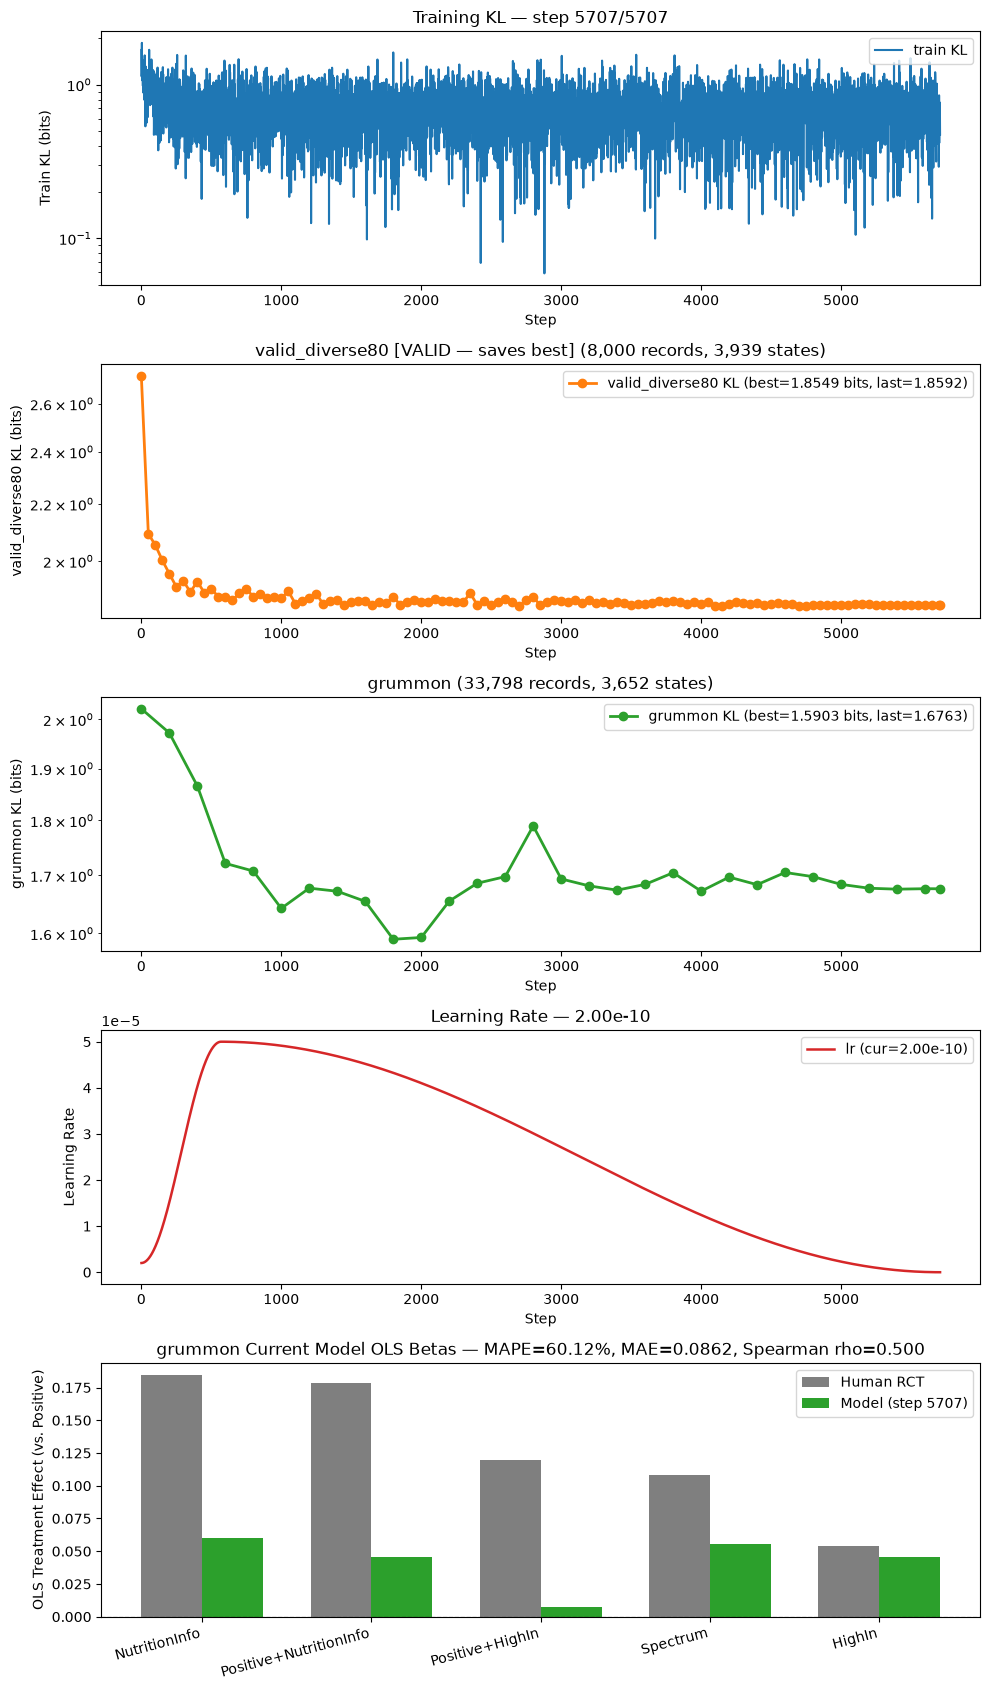

,epoch,step,train_kl,valid_diverse80_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,2.7238,2.0224,104.13,0.1164,0.0149,-0.9000
1,1,50,1.2479,2.0934,—,—,—,—,—
2,1,100,0.6506,2.0543,—,—,—,—,—
3,1,150,0.8987,2.0028,—,—,—,—,—
4,1,200,1.0118,1.9586,1.9721,81.27,0.0987,0.0111,-0.5000
5,1,250,0.7904,1.9161,—,—,—,—,—
6,1,300,1.0739,1.9354,—,—,—,—,—
7,1,350,0.5131,1.8995,—,—,—,—,—
8,1,400,0.9094,1.9330,1.8660,69.05,0.0856,0.0081,-0.1000
9,1,450,0.4365,1.8975,—,—,—,—,—


,human,model,abs_diff
NutritionInfo,0.1844,0.0603,0.1241
Positive+NutritionInfo,0.1788,0.0459,0.1330
Positive+HighIn,0.1194,0.0071,0.1124
Spectrum,0.1083,0.0556,0.0528
HighIn,0.0541,0.0453,0.0087


In [181]:
plotter = trainer.train()

## Train one-epoch 2

In [182]:
resume = False
val_every = [50, 500]
save_every = 50
epochs = 1
lr = 5e-4
k_schedule = DEFAULT_K_SCHEDULE   # (1, 2, 3, 4, 5, "full", "full")
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"
seed = 1
warmup_steps = 2000

if PRESET == "9b":
    trainer_cfg = dict(
        init_from="runs/kev-9b-resp-issp+twin2k-diversevalid-marginals/best",
        save_dir="runs/kev-9b-resp-issp+twin2k-diversevalid-marginals-ep2",
        weights_dtype="bf16",
        use_bf16=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        gradient_checkpointing=True,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        init_from="runs/kev-0.8b-resp-issp+twin2k-diversevalid-marginals/best",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-diversevalid-marginals-ep2",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = MarginalGroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    marginal_lookup=marginal_lookup,
    k_schedule=k_schedule,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=warmup_steps,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    seed=seed,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,MarginalGroupedTrainer
k_schedule,"(1, 2, 3, 4, 5, full, full)"
unique_personas,16338
trait_value_masks,181
run_name,kev-0.8b-resp-issp+twin2k-diversevalid-margina...
save_dir,runs/kev-0.8b-resp-issp+twin2k-diversevalid-ma...
init_from,runs/kev-0.8b-resp-issp+twin2k-diversevalid-ma...
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64


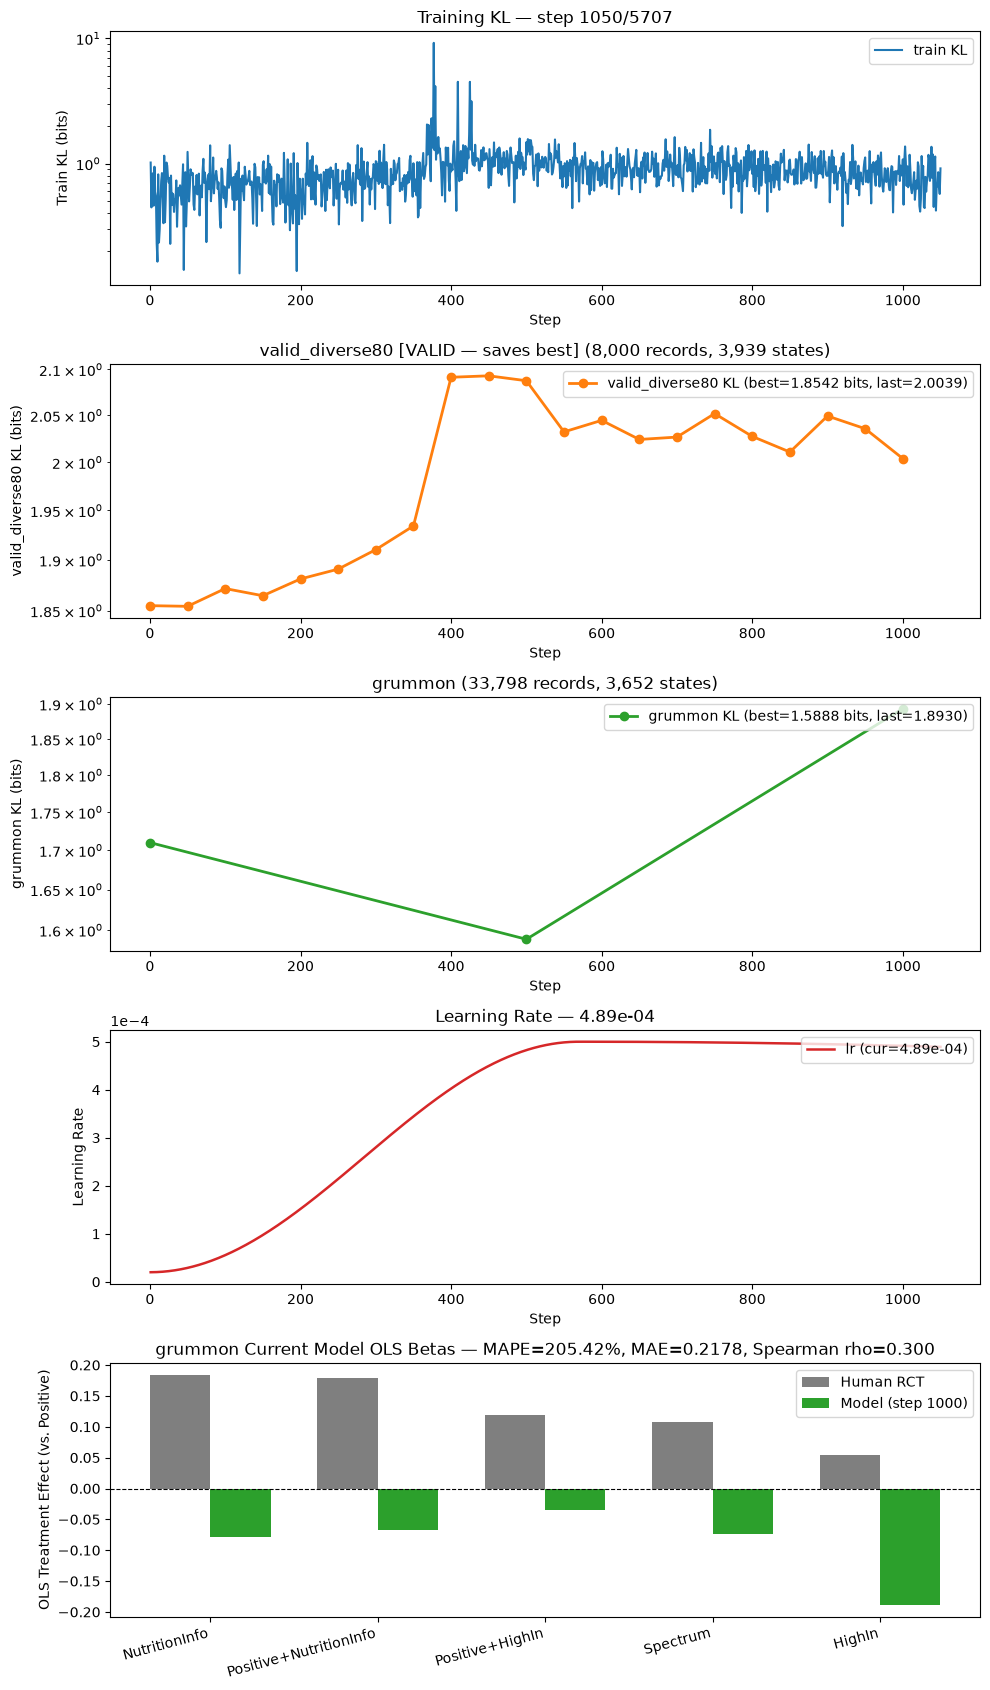

,epoch,step,train_kl,valid_diverse80_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,1.8549,1.7100,58.55,0.0838,0.0093,0.2000
1,1,50,1.2403,1.8542,—,—,—,—,—
2,1,100,0.5073,1.8716,—,—,—,—,—
3,1,150,0.9766,1.8646,—,—,—,—,—
4,1,200,0.6063,1.8811,—,—,—,—,—
5,1,250,0.8928,1.8908,—,—,—,—,—
6,1,300,1.0452,1.9103,—,—,—,—,—
7,1,350,1.0061,1.9342,—,—,—,—,—
8,1,400,0.8640,2.0914,—,—,—,—,—
9,1,450,0.6400,2.0930,—,—,—,—,—


,human,model,abs_diff
NutritionInfo,0.1844,-0.0782,0.2626
Positive+NutritionInfo,0.1788,-0.0678,0.2466
Positive+HighIn,0.1194,-0.0349,0.1543
Spectrum,0.1083,-0.0740,0.1823
HighIn,0.0541,-0.1890,0.2431


KeyboardInterrupt: 

In [183]:
plotter = trainer.train()

## Train 2 epochs

In [ ]:
resume = False
val_every = [50, 200]
save_every = 50
epochs = 2
lr = 5e-5
k_schedule = DEFAULT_K_SCHEDULE   # (1, 2, 3, 4, 5, "full", "full")
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"

if PRESET == "9b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-9b",
        save_dir="runs/kev-9b-resp-issp+twin2k-diversevalid-marginals-2epochs",
        weights_dtype="bf16",
        use_bf16=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        gradient_checkpointing=True,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-diversevalid-marginals-2epochs",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = MarginalGroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    marginal_lookup=marginal_lookup,
    k_schedule=k_schedule,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

In [ ]:
plotter = trainer.train()

## Optional: Probe VRAM directly on `trainer`

`trainer.probe_vram(grid)` reuses `trainer.train_one_step` with a zero-LR AdamW optimizer (and 2 micro-batches when `grad_accum_steps > 1`) inside `torch.random.fork_rng` so it measures exact steady-state peak VRAM without mutating model weights, RNG state, or creating empty plots.

In [ ]:
df_probe = trainer.probe_vram([
    (32, 16_000),
    (32, 20_000),
    (32, 24_000),
    (64, 24_000),
    (96, 36_000),
    (128, 48_000),
    (160, 60_000),
])
display(df_probe)

# You can also update grouping on the fly and recompute the schedule:
# trainer.set_grouping(max_questions_per_group=160, max_chars_per_group=60_000)